# Brain Tumor MRI Classification — ViT Fine-Tuning

Fine-tune `google/vit-base-patch16-224` to classify brain MRI scans into **glioma, meningioma, notumor, pituitary**.

**Before running (Kaggle):**
1. Settings → **Internet: On** (needed to download the model from Hugging Face)
2. Settings → **Accelerator: GPU T4**
3. **Add Data** → `masoudnickparvar/brain-tumor-mri-dataset`

> ⚠️ **Limitations:** The dataset's Training/ and Testing/ folders contain some identical / closely related images, so test accuracy may overestimate performance on genuinely unseen patients. This model is for learning and demonstration only and **must not be used for medical diagnosis**.

## 1. Setup

In [1]:
import os, json, random
from collections import Counter

import numpy as np
import torch
import matplotlib.pyplot as plt
from torchvision import datasets
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from transformers import (ViTForImageClassification, ViTImageProcessor,
                          get_linear_schedule_with_warmup)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

TRAIN_DIR = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training'
TEST_DIR  = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing'

# Fallback: Kaggle sometimes mounts datasets at /kaggle/input/<dataset-name>/
if not os.path.isdir(TRAIN_DIR):
    TRAIN_DIR = '/kaggle/input/brain-tumor-mri-dataset/Training'
    TEST_DIR  = '/kaggle/input/brain-tumor-mri-dataset/Testing'

assert os.path.isdir(TRAIN_DIR) and os.path.isdir(TEST_DIR), 'Dataset not found - check the path'

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

Device: cuda | Tesla T4


## 2. Class Distribution (before training)

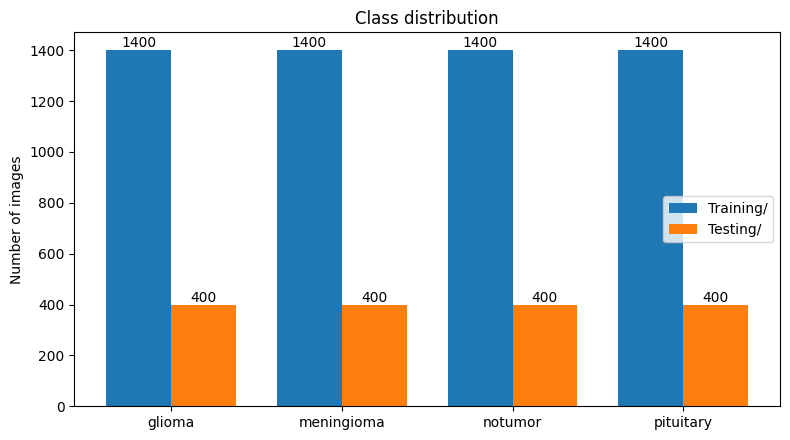

Train counts: {'glioma': 1400, 'meningioma': 1400, 'notumor': 1400, 'pituitary': 1400}
Test counts : {'glioma': 400, 'meningioma': 400, 'notumor': 400, 'pituitary': 400}


In [2]:
raw_train = datasets.ImageFolder(TRAIN_DIR)
raw_test  = datasets.ImageFolder(TEST_DIR)

train_counts = Counter(raw_train.targets)
test_counts  = Counter(raw_test.targets)
classes = raw_train.classes

x = np.arange(len(classes)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
b1 = ax.bar(x - w/2, [train_counts[i] for i in range(len(classes))], w, label='Training/')
b2 = ax.bar(x + w/2, [test_counts[i]  for i in range(len(classes))], w, label='Testing/')
ax.bar_label(b1); ax.bar_label(b2)
ax.set_xticks(x); ax.set_xticklabels(classes)
ax.set_ylabel('Number of images'); ax.set_title('Class distribution')
ax.legend(); plt.tight_layout(); plt.show()

print('Train counts:', {classes[k]: v for k, v in sorted(train_counts.items())})
print('Test counts :', {classes[k]: v for k, v in sorted(test_counts.items())})

## 3. Model and Image Processor

In [3]:
CHECKPOINT = 'google/vit-base-patch16-224'
NUM_CLASSES = 4

image_processor = ViTImageProcessor.from_pretrained(CHECKPOINT)
model = ViTForImageClassification.from_pretrained(
    CHECKPOINT, num_labels=NUM_CLASSES, ignore_mismatched_sizes=True
)
# ignore_mismatched_sizes=True: replace the 1000-class ImageNet head with a 4-class head

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([4])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([4, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


## 4. Dataset, Stratified 80/20 Split, DataLoaders

In [4]:
class BrainTumorDataset(Dataset):
    def __init__(self, root, processor):
        self.data = datasets.ImageFolder(root)
        self.processor = processor
        self.classes = self.data.classes

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image, label = self.data[idx]
        inputs = self.processor(images=image.convert('RGB'), return_tensors='pt')
        return {
            'pixel_values': inputs['pixel_values'].squeeze(0),
            'labels': torch.tensor(label)
        }

full_train_dataset = BrainTumorDataset(TRAIN_DIR, image_processor)
test_dataset = BrainTumorDataset(TEST_DIR, image_processor)

CLASS_NAMES = full_train_dataset.classes
assert CLASS_NAMES == test_dataset.classes, 'Class index order differs between train and test!'

# Store readable labels in the model config
model.config.id2label = {i: c for i, c in enumerate(CLASS_NAMES)}
model.config.label2id = {c: i for i, c in enumerate(CLASS_NAMES)}

indices = list(range(len(full_train_dataset)))
train_idx, val_idx = train_test_split(
    indices, test_size=0.20, random_state=42,
    stratify=full_train_dataset.data.targets
)
train_dataset = Subset(full_train_dataset, train_idx)
val_dataset = Subset(full_train_dataset, val_idx)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False, num_workers=2)

print('Classes:', CLASS_NAMES)
print('Train / val / test:', len(train_dataset), len(val_dataset), len(test_dataset))

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Train / val / test: 4480 1120 1600


## 5. Training (6 epochs, AdamW lr=2e-5, linear warmup)
Only the **validation** split is monitored. The checkpoint with the best validation accuracy is saved; the test set is not touched here.

In [5]:
EPOCHS, LR = 6, 2e-5
model.to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=(len(train_loader) * EPOCHS) // 10,
    num_training_steps=len(train_loader) * EPOCHS
)

train_losses, train_accuracies, val_accuracies = [], [], []
best_val_acc, best_epoch = -1.0, -1
os.makedirs('artifacts', exist_ok=True)

for epoch in range(EPOCHS):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for batch in train_loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        optimizer.zero_grad(set_to_none=True)
        outputs = model(**batch)
        loss = outputs.loss
        loss.backward()
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        correct += (outputs.logits.argmax(-1) == batch['labels']).sum().item()
        total += batch['labels'].size(0)

    train_loss = total_loss / len(train_loader)
    train_acc = correct / total

    model.eval()
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for batch in val_loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            preds = model(**batch).logits.argmax(dim=-1)
            val_correct += (preds == batch['labels']).sum().item()
            val_total += batch['labels'].size(0)
    val_acc = val_correct / val_total

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    flag = ''
    if val_acc > best_val_acc:
        best_val_acc, best_epoch = val_acc, epoch + 1
        torch.save(model.state_dict(), 'artifacts/vit_brain_tumor.pt')
        flag = '  <- best, checkpoint saved'

    print(f'Epoch {epoch+1}: loss={train_loss:.4f} '
          f'train_acc={train_acc:.4f} val_acc={val_acc:.4f}{flag}')

print(f'\nBest validation accuracy: {best_val_acc:.4f} (epoch {best_epoch})')

Epoch 1: loss=0.6567 train_acc=0.7467 val_acc=0.9366  <- best, checkpoint saved
Epoch 2: loss=0.0971 train_acc=0.9714 val_acc=0.9705  <- best, checkpoint saved
Epoch 3: loss=0.0234 train_acc=0.9964 val_acc=0.9670
Epoch 4: loss=0.0097 train_acc=0.9996 val_acc=0.9821  <- best, checkpoint saved
Epoch 5: loss=0.0050 train_acc=1.0000 val_acc=0.9812
Epoch 6: loss=0.0041 train_acc=1.0000 val_acc=0.9821

Best validation accuracy: 0.9821 (epoch 4)


## 6. Learning Curves

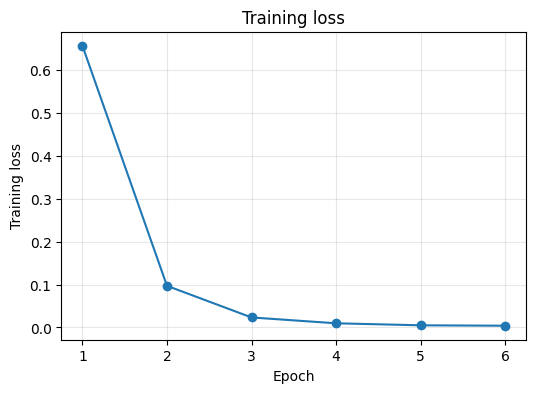

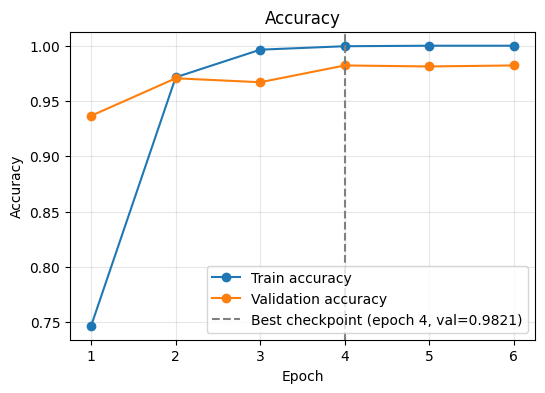

In [6]:
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(6, 4))
plt.plot(epochs, train_losses, marker='o')
plt.xlabel('Epoch'); plt.ylabel('Training loss'); plt.title('Training loss')
plt.grid(alpha=0.3); plt.show()

plt.figure(figsize=(6, 4))
plt.plot(epochs, train_accuracies, marker='o', label='Train accuracy')
plt.plot(epochs, val_accuracies, marker='o', label='Validation accuracy')
plt.axvline(best_epoch, color='gray', linestyle='--',
            label=f'Best checkpoint (epoch {best_epoch}, val={best_val_acc:.4f})')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Accuracy')
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 7. Final Held-out Test Evaluation (run once, after model selection)

Selected checkpoint: epoch 4 (val acc 0.9821)
Final Test Accuracy: 0.9381

              precision    recall  f1-score   support

      glioma     0.9845    0.7950    0.8797       400
  meningioma     0.8758    0.9700    0.9205       400
     notumor     0.9412    1.0000    0.9697       400
   pituitary     0.9658    0.9875    0.9765       400

    accuracy                         0.9381      1600
   macro avg     0.9418    0.9381    0.9366      1600
weighted avg     0.9418    0.9381    0.9366      1600



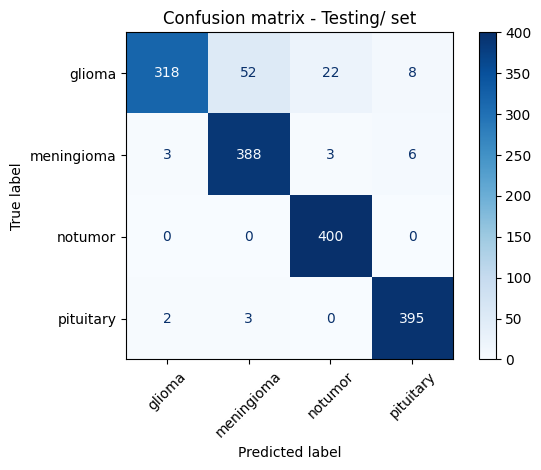

In [7]:
model.load_state_dict(torch.load('artifacts/vit_brain_tumor.pt',
                                 map_location=DEVICE, weights_only=True))
model.to(DEVICE)
model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for batch in test_loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        predictions = model(**batch).logits.argmax(dim=-1)
        y_true.extend(batch['labels'].cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

test_acc = accuracy_score(y_true, y_pred)
print(f'Selected checkpoint: epoch {best_epoch} (val acc {best_val_acc:.4f})')
print('Final Test Accuracy:', round(test_acc, 4))
print()
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=CLASS_NAMES, xticks_rotation=45, cmap='Blues'
)
plt.title('Confusion matrix - Testing/ set'); plt.tight_layout(); plt.show()

## 8. Save Artifacts

In [8]:
# Weights were already saved by the training loop (best validation epoch) - do NOT overwrite them.
with open('artifacts/class_names.json', 'w') as f:
    json.dump(CLASS_NAMES, f)

image_processor.save_pretrained('artifacts/image_processor')
print('Saved weights, class labels, and image processor.')

# Zip everything for a single download from the Kaggle Output tab
import shutil
shutil.make_archive('/kaggle/working/artifacts', 'zip', '.', 'artifacts')
for root, _, files in os.walk('artifacts'):
    for name in files:
        p = os.path.join(root, name)
        print(f'{p:55s} {os.path.getsize(p)/1e6:8.2f} MB')

Saved weights, class labels, and image processor.
artifacts/class_names.json                                  0.00 MB
artifacts/vit_brain_tumor.pt                              343.28 MB
artifacts/image_processor/preprocessor_config.json          0.00 MB


## 9. Download
Open the notebook's **Output** panel (`/kaggle/working/`) and download `artifacts.zip`. Unzip it into the repository root so you have:

```
artifacts/
├── vit_brain_tumor.pt
├── class_names.json
└── image_processor/
    └── preprocessor_config.json
```

In [9]:
from IPython.display import FileLink
FileLink('artifacts.zip')

/kaggle/working/artifacts.zip

In [10]:
import shutil
shutil.make_archive('/kaggle/working/artifacts', 'zip', '/kaggle/working', 'artifacts')
!ls -lh /kaggle/working/

total 304M
drwxr-xr-x 3 root root 4.0K Nov 18 11:28 artifacts
-rw-r--r-- 1 root root 304M Nov 18 11:28 artifacts.zip


In [11]:
import os, shutil
os.chdir('/kaggle/working')

if os.path.exists('artifacts/vit_brain_tumor.pt'):
    shutil.make_archive('artifacts', 'zip', '.', 'artifacts')
    print('Zip created!')
    !ls -lh /kaggle/working/
else:
    print('Trained model NOT found - the session was reset.')
    !ls -lh /kaggle/working/

Zip created!
total 304M
drwxr-xr-x 3 root root 4.0K Nov 18 11:28 artifacts
-rw-r--r-- 1 root root 304M Nov 18 11:28 artifacts.zip
